# Character-level Transformer spell-checker

Translate noisy text (`fr`) into corrected text (`en`) using a TensorFlow/Keras encoder-decoder Transformer trained **from scratch** on the [GitHub Typo Corpus](https://github.com/mhagiwara/github-typo-corpus). These suffixes denote correction direction, not French and English.

**Modes.** `MODE = 'cpu'` (the default, and the source of the saved outputs) is a genuine but reduced experiment sized for a CPU-only machine: a Transformer with two blocks per side is trained for two epochs on every training pair whose source and target fit within 128 characters. Checkpoint selection uses a seeded 2,000-pair development subset, and evaluation uses a seeded 4,000-pair sample of the *remaining* in-range development pairs, so reported scores are held out from checkpoint selection. A fresh CPU run takes on the order of an hour on a laptop CPU (measured times are printed and saved; keep the machine awake); later runs reuse the matching saved checkpoint unless `REUSE_TRAINED = False`. Batch progress is appended to `training_progress.log` in the output directory. `MODE = 'smoke'` is a quick pipeline test only, and `MODE = 'full'` is the larger GPU-scale configuration (all lengths up to 512, four blocks per side). Even a trained model cannot guarantee errorless output.

## Environment
Use Python 3.11 or 3.12 and a TensorFlow-compatible kernel. On this machine, select **Spell-checker (TensorFlow CPU)** from the notebook's kernel picker; that registered Python 3.12 kernel already has the required packages. The notebook kernel selection is separate from the workspace Python interpreter. If an old kernel is active, switch kernels and restart before running all cells. Check `import sys; print(sys.executable)` in a cell to confirm which Python is running.

On another machine, install into your chosen compatible kernel with `%pip install tensorflow==2.20.0 matplotlib==3.11.2`; Jupyter also needs `ipykernel`. Restart the kernel after installation. Do not install into an unrelated Python environment to repair a notebook import. The notebook uses Keras 3 through `tf.keras` and no pretrained weights or external model downloads.

For NVIDIA GPU training, use a compatible Linux/WSL2 environment with `tensorflow[and-cuda]==2.20.0`, or a compatible Colab GPU runtime. Modern native Windows TensorFlow wheels are CPU-only; Windows ARM64 requires a supported runtime, such as x64 Python under emulation for CPU verification. Dependency installation is deliberate, not automatic.

## Data and limitations
Keep the four supplied `*.tok.*.txt` files in `gtc` next to this notebook. Run from this directory or the repository root. Do not retokenize or resplit `all.tsv`.

The actual supplied files use U+2581 (`▁`), **not `_`**, for whitespace and use the ASCII apostrophe. Tokens are space-separated characters; `#` represents unsupported characters. Mapping to `#` is irreversible and may alter URLs, code, Unicode, and other unsupported text. Raw whitespace is normalized character-by-character to spaces, without stripping or collapsing it. Literal underscores are unsupported characters, not whitespace. We retain case and unchanged training examples.

Maximum input/output content length is 512 characters in smoke/full mode and 128 characters in CPU mode, excluding boundary tokens. Longer inputs are rejected, never silently truncated. Empty input is a no-op. Prediction returns `{'corrected_text': ..., 'changed': ...}`; the boolean compares with the original raw input, so normalization alone can count as a change. There is no separate error-span classifier or highlighting UI.

In [1]:
import json
import math
import os
import string
import tempfile
import time
from collections import Counter
from itertools import zip_longest
from pathlib import Path
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

MODE = 'cpu'  # 'smoke' = pipeline test, 'cpu' = reduced real experiment, 'full' = GPU-scale run.
REUSE_TRAINED = True  # Reuse a matching saved checkpoint for this mode; set False to force retraining.
if MODE not in {'smoke', 'cpu', 'full'}:
    raise ValueError("MODE must be 'smoke', 'cpu' or 'full'")
SEED = 574
MAX_CHARS = 512  # Longest sequence in the supplied corpus.
MODEL_MAX_CHARS = 128 if MODE == 'cpu' else MAX_CHARS  # Longest input/output the model is trained and used for.
DECODE_MARGIN = 50  # Generated text may exceed the input length by at most this many characters.
CPU_VALIDATION_PAIRS, CPU_EVALUATION_PAIRS = 2000, 4000
SPACE = '\u2581'
PAD, BOS, EOS = 0, 1, 2
ALLOWED = set(string.ascii_letters + string.digits + ".,!?'#-" + SPACE)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

candidates = [Path.cwd() / 'gtc', Path.cwd() / 'Assignment 2' / 'gtc']
DATA_DIR = next((p for p in candidates if (p / 'train.tok.fr.txt').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Run from the repository root or Assignment 2; expected gtc/train.tok.fr.txt')
OUTPUT_DIR = Path(os.environ.get('SPELLCHECK_OUTPUT_DIR', str(DATA_DIR.parent / 'outputs' / MODE)))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SETTINGS = {
    'smoke': dict(d_model=32, num_heads=2, ff_dim=64, num_layers=1, batch_size=8, epochs=2, warmup=10, patience=5),
    'cpu': dict(d_model=128, num_heads=4, ff_dim=512, num_layers=2, batch_size=64, epochs=2, warmup=1500, patience=2),
    'full': dict(d_model=128, num_heads=4, ff_dim=512, num_layers=4, batch_size=32, epochs=30, warmup=4000, patience=5),
}[MODE]
CONFIG = dict(vocab_size=0, max_chars=MODEL_MAX_CHARS, d_model=SETTINGS['d_model'], num_heads=SETTINGS['num_heads'],
              ff_dim=SETTINGS['ff_dim'], num_layers=SETTINGS['num_layers'], dropout=0.1)
BATCH_SIZE, EPOCHS = SETTINGS['batch_size'], SETTINGS['epochs']
WARMUP, PATIENCE = SETTINGS['warmup'], SETTINGS['patience']
DECODE_LIMIT = 32 if MODE == 'smoke' else MODEL_MAX_CHARS
print('TensorFlow:', tf.__version__, '| Keras:', tf.keras.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
print('Mode:', MODE, '| data:', DATA_DIR, '| outputs:', OUTPUT_DIR)
if MODE == 'smoke':
    print('SMOKE ONLY: tiny subsets/model; generation capped at 32 characters. Not evidence of correction quality.')
elif MODE == 'cpu':
    print(f'CPU EXPERIMENT: real training on pairs up to {MODEL_MAX_CHARS} characters; longer inputs are rejected.')


TensorFlow: 2.20.0 | Keras: 3.15.1
GPUs: []
Mode: cpu | data: C:\Github\NLP_AI-574\Assignment 2\gtc | outputs: C:\Github\NLP_AI-574\Assignment 2\outputs\cpu
CPU EXPERIMENT: real training on pairs up to 128 characters; longer inputs are rejected.


## 1. Validate aligned pairs and construct the vocabulary
Scan both splits completely, even in smoke mode. Skip only pairs where **both** sides are blank and report them. Missing or malformed rows fail with filename/line context. Learn a deterministic shared source/target character vocabulary from training only, then validate development symbols against it. Padding, BOS and EOS have separate IDs; unsupported raw characters use the existing `#` token, not a silent unknown ID.

Expected supplied corpus: 242,306 training rows (two paired blanks) and 12,752 development rows; the longest sequence is 512 tokens. Smoke training selects 32 short training pairs and eight short development pairs. CPU mode trains on every nonblank training pair whose source and target both fit within 128 characters (unchanged pairs included), and uses a seeded 2,000-pair in-range development subset for checkpoint selection; evaluation draws a seeded 4,000-pair sample from the other in-range development pairs. Full mode retains all nonblank pairs, including long and unchanged examples.

Training batches are grouped by length (bucketing) so short pairs are not padded to the longest pair in a random batch. This only reduces wasted computation; no pair is truncated.

In [2]:
def read_pairs(source_path, target_path):
    pairs, stats = [], Counter()
    with source_path.open(encoding='utf-8') as src, target_path.open(encoding='utf-8') as dst:
        for line_no, (a, b) in enumerate(zip_longest(src, dst), 1):
            stats['rows'] += 1
            if a is None or b is None:
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: unpaired row')
            aa, bb = a.split(), b.split()
            if not aa and not bb:
                stats['paired_blanks_skipped'] += 1
                continue
            if not aa or not bb:
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: one-sided blank')
            if any(len(t) != 1 or t not in ALLOWED for t in aa + bb):
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: unsupported character token')
            length = max(len(aa), len(bb))
            if length > MAX_CHARS:
                raise ValueError(f'{source_path.name}/{target_path.name}:{line_no}: exceeds {MAX_CHARS} tokens')
            pair = (''.join(aa), ''.join(bb))
            pairs.append(pair)
            stats['unchanged'] += pair[0] == pair[1]
            stats['max_tokens'] = max(stats['max_tokens'], length)
    if not pairs:
        raise ValueError(f'{source_path}: no usable pairs')
    stats['usable_pairs'] = len(pairs)
    return pairs, dict(stats)


train_pairs, train_stats = read_pairs(DATA_DIR / 'train.tok.fr.txt', DATA_DIR / 'train.tok.en.txt')
dev_pairs, dev_stats = read_pairs(DATA_DIR / 'dev.tok.fr.txt', DATA_DIR / 'dev.tok.en.txt')
print('Training:', train_stats)
print('Development:', dev_stats)
characters = sorted({c for pair in train_pairs for text in pair for c in text})
id_to_token = ['<pad>', '<bos>', '<eos>'] + characters
token_to_id = {token: i for i, token in enumerate(id_to_token)}
unseen_dev = {c for pair in dev_pairs for text in pair for c in text} - set(characters)
if unseen_dev:
    raise ValueError(f'Development characters absent from training: {sorted(unseen_dev)}')
if not {SPACE, '#'} <= set(characters):
    raise ValueError('Training vocabulary must contain the corpus whitespace marker and #')
CONFIG['vocab_size'] = len(id_to_token)


def normalize_raw(text, vocabulary=None):
    vocabulary = token_to_id if vocabulary is None else vocabulary
    if not isinstance(text, str):
        raise TypeError('Input text must be a string')
    if len(text) > MODEL_MAX_CHARS:
        raise ValueError(f'Input has {len(text)} characters; maximum is {MODEL_MAX_CHARS}')
    return ''.join(SPACE if c.isspace() else c if c in vocabulary and c != SPACE else '#' for c in text)


def encode_content(text):
    if len(text) > MAX_CHARS:
        raise ValueError(f'Content exceeds {MAX_CHARS} characters')
    return [token_to_id[c] for c in text]


def display_content(text):
    return text.replace(SPACE, ' ')


def edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, 1):
        current = [i]
        for j, char_b in enumerate(b, 1):
            current.append(min(current[-1] + 1, previous[j] + 1, previous[j - 1] + (char_a != char_b)))
        previous = current
    return previous[-1]


def show_table(headers, rows):
    def escape(value):
        return str(value).replace('|', '&#124;').replace('\n', '<br>')
    lines = ['| ' + ' | '.join(map(escape, headers)) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(escape, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def short_subset(pairs, count):
    subset = [pair for pair in pairs if max(map(len, pair)) <= 80][:count]
    if len(subset) != count:
        raise ValueError(f'Need {count} short pairs for smoke mode')
    return subset


def within_model_length(pair):
    return max(len(pair[0]), len(pair[1])) <= MODEL_MAX_CHARS


validation_indices = None
if MODE == 'smoke':
    training_pairs, validation_pairs = short_subset(train_pairs, 32), short_subset(dev_pairs, 8)
elif MODE == 'cpu':
    training_pairs = [pair for pair in train_pairs if within_model_length(pair)]
    dev_in_range = [i for i, pair in enumerate(dev_pairs) if within_model_length(pair)]
    if len(dev_in_range) <= CPU_VALIDATION_PAIRS:
        raise ValueError('Not enough in-range development pairs for a disjoint validation subset')
    validation_indices = sorted(np.random.default_rng(SEED).choice(dev_in_range, CPU_VALIDATION_PAIRS,
                                                                   replace=False).tolist())
    validation_pairs = [dev_pairs[i] for i in validation_indices]
else:
    training_pairs, validation_pairs = train_pairs, dev_pairs


def make_dataset(pairs, training=False):
    def generate():
        for source, target in pairs:
            source_ids = [BOS] + encode_content(source) + [EOS]
            target_ids = [BOS] + encode_content(target) + [EOS]
            yield ((source_ids, target_ids[:-1]), target_ids[1:])
    vector = tf.TensorSpec(shape=(None,), dtype=tf.int32)
    ds = tf.data.Dataset.from_generator(generate, output_signature=((vector, vector), vector))
    ds = ds.apply(tf.data.experimental.assert_cardinality(len(pairs)))
    if training:
        # Length buckets keep similarly sized pairs together, reducing padding work without truncating anything.
        boundaries = [b for b in (24, 40, 56, 72, 88, 104, 120, 160, 224, 320, 416) if b < MODEL_MAX_CHARS + 2]
        ds = ds.shuffle(min(len(pairs), 50000), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.bucket_by_sequence_length(
            lambda inputs, labels: tf.maximum(tf.shape(inputs[0])[0], tf.shape(inputs[1])[0]),
            bucket_boundaries=boundaries, bucket_batch_sizes=[BATCH_SIZE] * (len(boundaries) + 1),
            padding_values=((PAD, PAD), PAD))
    else:
        ds = ds.padded_batch(BATCH_SIZE, padded_shapes=(([None], [None]), [None]),
                             padding_values=((PAD, PAD), PAD))
    return ds.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(training_pairs, training=True)
dev_ds = make_dataset(validation_pairs)
print('Vocabulary:', len(id_to_token), '| training/validation pairs:', len(training_pairs), len(validation_pairs))


Training: {'rows': 242306, 'paired_blanks_skipped': 2, 'unchanged': 8398, 'max_tokens': 512, 'usable_pairs': 242304}
Development: {'rows': 12752, 'unchanged': 471, 'max_tokens': 512, 'usable_pairs': 12752}


Vocabulary: 73 | training/validation pairs: 196752 2000


## Data exploration (rubric: 20 points)
Counts, character frequencies and length statistics below use **all usable pairs**, even in smoke mode. Edit-distance analysis uses a seeded uniform sample of at most 256 pairs per split to bound quadratic dynamic-programming work. This sample measures correction size, not a linguistic error taxonomy or model quality.

The unchanged fraction measures how often copying is already correct. Length distributions inform positional capacity and padding cost. The `#` prevalence quantifies information lost in preprocessing. GitHub edits include code and identifiers as well as prose; displayed examples illustrate this domain but do not estimate its prevalence. A character substitution can represent spelling, punctuation, code, or another change: do not infer semantic error categories from edit distance alone.

| Split | Raw rows | Usable | Blank pairs skipped | Unchanged | Pairs with # | # share (both sides) |
| --- | --- | --- | --- | --- | --- | --- |
| training | 242306 | 242304 | 2 | 3.47% | 82.02% | 4.04% |
| development | 12752 | 12752 | 0 | 3.69% | 81.57% | 4.04% |

| Split | Side | Min | Q25 | Median | Q75 | Q95 | Max |
| --- | --- | --- | --- | --- | --- | --- | --- |
| training | source | 3.0 | 45.0 | 71.0 | 104.0 | 294.0 | 512.0 |
| training | target | 3.0 | 46.0 | 71.0 | 105.0 | 295.0 | 512.0 |
| development | source | 4.0 | 45.0 | 71.0 | 102.0 | 296.0 | 511.0 |
| development | target | 4.0 | 46.0 | 71.0 | 103.0 | 296.0 | 512.0 |

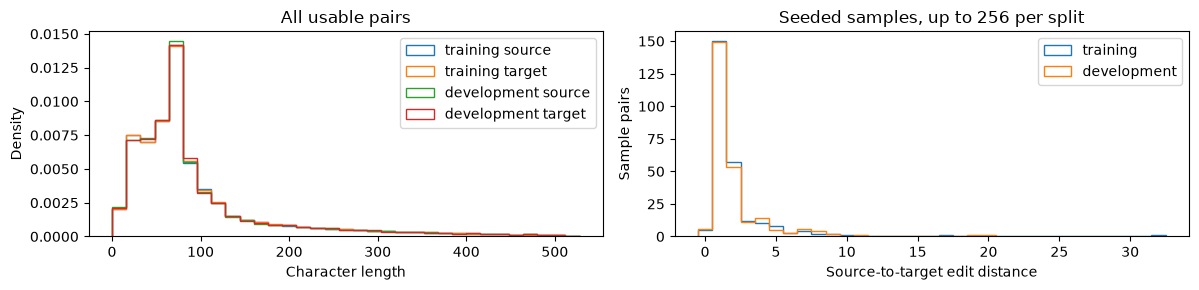

| Split | Edit-distance sample size | Mean | Median |
| --- | --- | --- | --- |
| training | 256 | 2.03 | 1.0 |
| development | 256 | 2.07 | 1.0 |

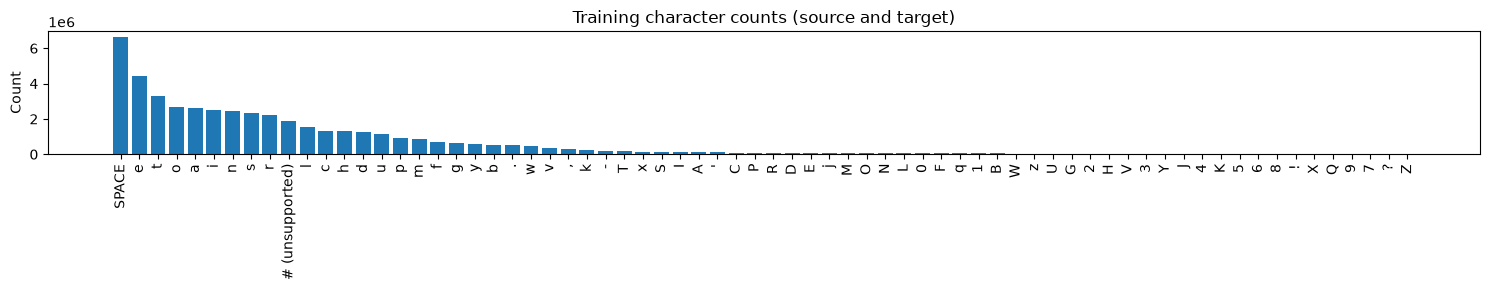

| Training index (after blank filtering) | Noisy input | Clean target | Edit distance |
| --- | --- | --- | --- |
| 23 | '# - IGPU property enable-cfl-backlight-fix turns patch on' | '# - IGPU property enable-cfl-backlight-fix turns patch on' | 0 |
| 0 | 'IN.User.authorize#function###' | 'IN.User.authorize#function## #' | 1 |
| 9611 | '# #' | '# #' | 0 |
| 311 | "##onFileUploadFinish###imageUploaded##event###. If ##src## is specified this event is fired when component gets a responce from the server, also in this case event has field #serverResponse# which contains object returned by the server. If ##src## is not specified it's fired immediately after an image#s# dropped into file-drop zone of choosed in file browser. So what you can do, is not specify ##src## to handle upload yourself, for exapmple send the image into firebase storage. To get file use #event.file#." | "##onFileUploadFinish###imageUploaded##event###. If ##url## is specified this event is fired when component gets a responce from the server, also in this case event has field #serverResponse# which contains object returned by the server. If ##url## is not specified it's fired immediately after an image#s# dropped into file-drop zone of choosed in file browser. So what you can do, is not specify ##url## to handle upload yourself, for exapmple send the image into firebase storage. To get file use #event.file#." | 6 |
| 50005 | '4. To filter by multiple attributes with the #AMD# operator#' | '4. To filter by multiple attributes with the #AND# operator#' | 1 |
| 123854 | "# Get all of the video's comment." | "# Get all of the video's comments." | 1 |
| 201218 | '#description## #Monitor openstack platform using the SignalFx collectd agent.#,' | '#description## #Monitor OpenStack platform using the SignalFx collectd agent.#,' | 2 |

7282

In [3]:
def sample_indices(size, count, seed=SEED):
    if size < 0 or count < 0:
        raise ValueError('Sample sizes must be nonnegative')
    return sorted(np.random.default_rng(seed).choice(size, min(count, size), replace=False).tolist())


exploration = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
summary_rows, length_rows = [], []
for name, pairs, stats in [('training', train_pairs, train_stats), ('development', dev_pairs, dev_stats)]:
    lengths = np.array([[len(s), len(t)] for s, t in pairs])
    frequencies = Counter(c for pair in pairs for text in pair for c in text)
    marker_pairs = sum('#' in s or '#' in t for s, t in pairs)
    indices = sample_indices(len(pairs), 256)
    distances = [edit_distance(*pairs[i]) for i in indices]
    exploration[name] = dict(usable_pairs=len(pairs), paired_blanks_skipped=stats.get('paired_blanks_skipped', 0),
                             unchanged=stats['unchanged'], changed=len(pairs) - stats['unchanged'],
                             marker_pairs=marker_pairs, marker_characters=frequencies['#'],
                             total_characters=sum(frequencies.values()),
                             distance_sample_indices=indices, distance_sample_size=len(indices),
                             distance_mean=float(np.mean(distances)), distance_median=float(np.median(distances)))
    summary_rows.append([name, stats['rows'], len(pairs), stats.get('paired_blanks_skipped', 0),
                         f"{stats['unchanged'] / len(pairs):.2%}", f'{marker_pairs / len(pairs):.2%}',
                         f"{frequencies['#'] / sum(frequencies.values()):.2%}"])
    for column, label in enumerate(['source', 'target']):
        quantiles = np.quantile(lengths[:, column], [0, .25, .5, .75, .95, 1])
        length_rows.append([name, label] + [f'{v:.1f}' for v in quantiles])
        axes[0].hist(lengths[:, column], bins=np.arange(0, MAX_CHARS + 17, 16), histtype='step',
                     density=True, label=name + ' ' + label)
    axes[1].hist(distances, bins=np.arange(0, max(distances) + 2) - .5, histtype='step', label=name)
show_table(['Split', 'Raw rows', 'Usable', 'Blank pairs skipped', 'Unchanged', 'Pairs with #', '# share (both sides)'], summary_rows)
show_table(['Split', 'Side', 'Min', 'Q25', 'Median', 'Q75', 'Q95', 'Max'], length_rows)
axes[0].set(xlabel='Character length', ylabel='Density', title='All usable pairs')
axes[1].set(xlabel='Source-to-target edit distance', ylabel='Sample pairs', title='Seeded samples, up to 256 per split')
for ax in axes:
    ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'corpus_distributions.png', dpi=150)
plt.show()
show_table(['Split', 'Edit-distance sample size', 'Mean', 'Median'],
           [[name, data['distance_sample_size'], f"{data['distance_mean']:.2f}", data['distance_median']]
            for name, data in exploration.items()])

training_frequencies = Counter(c for pair in train_pairs for text in pair for c in text)
frequency_items = training_frequencies.most_common()
fig, ax = plt.subplots(figsize=(15, 3))
ax.bar(['SPACE' if c == SPACE else '# (unsupported)' if c == '#' else c for c, _ in frequency_items],
       [count for _, count in frequency_items])
ax.set(title='Training character counts (source and target)', ylabel='Count')
ax.tick_params(axis='x', labelrotation=90)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'character_frequencies.png', dpi=150)
plt.show()

example_indices = list(dict.fromkeys([
    next(i for i, (s, t) in enumerate(train_pairs) if s == t),
    next(i for i, (s, t) in enumerate(train_pairs) if s != t),
    min(range(len(train_pairs)), key=lambda i: max(map(len, train_pairs[i]))),
    max(range(len(train_pairs)), key=lambda i: max(map(len, train_pairs[i])))] + sample_indices(len(train_pairs), 3)))
show_table(['Training index (after blank filtering)', 'Noisy input', 'Clean target', 'Edit distance'],
           [[i, repr(display_content(train_pairs[i][0])), repr(display_content(train_pairs[i][1])),
             edit_distance(*train_pairs[i])] for i in example_indices])
(OUTPUT_DIR / 'exploration.json').write_text(json.dumps(exploration, indent=2), encoding='utf-8')


## 2. Encoder-decoder Transformer
The encoder reads the noisy sequence bidirectionally. Each decoder block has causal self-attention, encoder cross-attention, and a position-wise feed-forward network, with residual connections, layer normalization and dropout. Training uses teacher forcing: decoder input is `BOS + target`, and labels are `target + EOS`.

### Architecture rationale (rubric: Model Building, 60 points)
Full mode uses four encoder and four decoder blocks, width 128, four attention heads and feed-forward width 512: a modest starting configuration for a small character vocabulary, not a tuned optimum. CPU mode keeps the same width, heads and feed-forward size but uses two blocks per side, two epochs and a 128-character positional range so that training finishes on a laptop CPU; this is a compute trade-off, not a tuned choice. Each head has width 32. Dropout 0.1 regularizes residual updates; training/dev curves should be inspected for underfitting or overfitting before changing it. The maximum length fixes positional capacity, rather than truncating data. Separate BOS/EOS distinguish sequence boundaries from padding. Masking prevents future-target leakage and padding-dependent learning signals. The warmup/inverse-square-root schedule stabilizes early updates and decreases the learning rate later; best development loss selects an inference checkpoint, while autoregressive metrics test whether that checkpoint actually corrects text.

Boolean masks exclude padding keys **and queries** and prevent access to future decoder tokens. Learned positional embeddings have capacity `MODEL_MAX_CHARS + 2` (514 in smoke/full mode, 130 in CPU mode: content characters plus two boundary tokens). Loss is the mean cross-entropy over non-padding tokens in each batch; epoch loss averages these batch losses. Token accuracy accumulates non-padding correct/total counts across the epoch. No padding contributes to either measure.

In [4]:
def attention_masks(source, target):
    src_ok, tgt_ok = tf.not_equal(source, PAD), tf.not_equal(target, PAD)
    src_mask = src_ok[:, :, None] & src_ok[:, None, :]
    length = tf.shape(target)[1]
    causal = tf.range(length)[:, None] >= tf.range(length)[None, :]
    tgt_mask = tgt_ok[:, :, None] & tgt_ok[:, None, :] & causal[None, :, :]
    cross_mask = tgt_ok[:, :, None] & src_ok[:, None, :]
    return src_mask, tgt_mask, cross_mask


class TokenPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, vocab_size, d_model, capacity):
        super().__init__()
        self.tokens = tf.keras.layers.Embedding(vocab_size, d_model)
        self.positions = tf.keras.layers.Embedding(capacity, d_model)
        self.scale = math.sqrt(d_model)

    def call(self, ids):
        return self.tokens(ids) * self.scale + self.positions(tf.range(tf.shape(ids)[1]))


class EncoderBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout):
        super().__init__()
        self.attention = tf.keras.layers.MultiHeadAttention(num_heads, d_model // num_heads, dropout=dropout)
        self.ff = tf.keras.Sequential([tf.keras.layers.Dense(ff_dim, activation='relu'), tf.keras.layers.Dense(d_model)])
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = tf.keras.layers.Dropout(dropout)
        self.drop2 = tf.keras.layers.Dropout(dropout)

    def call(self, x, attention_mask, training=False):
        update = self.attention(x, x, attention_mask=attention_mask, training=training)
        x = self.norm1(x + self.drop1(update, training=training))
        return self.norm2(x + self.drop2(self.ff(x), training=training))


class DecoderBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout):
        super().__init__()
        self.self_attention = tf.keras.layers.MultiHeadAttention(num_heads, d_model // num_heads, dropout=dropout)
        self.cross_attention = tf.keras.layers.MultiHeadAttention(num_heads, d_model // num_heads, dropout=dropout)
        self.ff = tf.keras.Sequential([tf.keras.layers.Dense(ff_dim, activation='relu'), tf.keras.layers.Dense(d_model)])
        self.norms = [tf.keras.layers.LayerNormalization(epsilon=1e-6) for _ in range(3)]
        self.drops = [tf.keras.layers.Dropout(dropout) for _ in range(3)]

    def call(self, x, encoded, self_mask, cross_mask, training=False):
        update = self.self_attention(x, x, attention_mask=self_mask, training=training)
        x = self.norms[0](x + self.drops[0](update, training=training))
        update = self.cross_attention(x, encoded, attention_mask=cross_mask, training=training)
        x = self.norms[1](x + self.drops[1](update, training=training))
        return self.norms[2](x + self.drops[2](self.ff(x), training=training))


class SpellTransformer(tf.keras.Model):
    def __init__(self, vocab_size, max_chars, d_model, num_heads, ff_dim, num_layers, dropout):
        super().__init__()
        if d_model % num_heads:
            raise ValueError('d_model must be divisible by num_heads')
        self.src_embedding = TokenPositionEmbedding(vocab_size, d_model, max_chars + 2)
        self.tgt_embedding = TokenPositionEmbedding(vocab_size, d_model, max_chars + 2)
        self.src_dropout = tf.keras.layers.Dropout(dropout)
        self.tgt_dropout = tf.keras.layers.Dropout(dropout)
        args = (d_model, num_heads, ff_dim, dropout)
        self.encoders = [EncoderBlock(*args) for _ in range(num_layers)]
        self.decoders = [DecoderBlock(*args) for _ in range(num_layers)]
        self.projection = tf.keras.layers.Dense(vocab_size)

    def encode(self, source, training=False):
        src_ok = tf.not_equal(source, PAD)
        src_mask = src_ok[:, :, None] & src_ok[:, None, :]
        encoded = self.src_dropout(self.src_embedding(source), training=training)
        for block in self.encoders:
            encoded = block(encoded, attention_mask=src_mask, training=training)
        return encoded

    def decode(self, source, encoded, target, training=False):
        _, tgt_mask, cross_mask = attention_masks(source, target)
        decoded = self.tgt_dropout(self.tgt_embedding(target), training=training)
        for block in self.decoders:
            decoded = block(decoded, encoded, self_mask=tgt_mask, cross_mask=cross_mask, training=training)
        return self.projection(decoded)

    def call(self, inputs, training=False):
        source, target = inputs
        return self.decode(source, self.encode(source, training=training), target, training=training)


def masked_loss(labels, logits):
    per_token = tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
    mask = tf.cast(labels != PAD, per_token.dtype)
    return tf.math.divide_no_nan(tf.reduce_sum(per_token * mask), tf.reduce_sum(mask))


class MaskedAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name='masked_accuracy', **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_weight(name='correct', initializer='zeros')
        self.total = self.add_weight(name='total', initializer='zeros')

    def update_state(self, labels, logits, sample_weight=None):
        valid = tf.cast(labels != PAD, self.dtype)
        if sample_weight is not None:
            valid *= tf.cast(sample_weight, self.dtype)
        correct = tf.cast(tf.equal(tf.argmax(logits, axis=-1, output_type=labels.dtype), labels), self.dtype)
        self.correct.assign_add(tf.reduce_sum(correct * valid))
        self.total.assign_add(tf.reduce_sum(valid))

    def result(self):
        return tf.math.divide_no_nan(self.correct, self.total)

    def reset_state(self):
        self.correct.assign(0)
        self.total.assign(0)


model = SpellTransformer(**CONFIG)
batch_inputs, batch_labels = next(iter(train_ds))
batch_logits = model(batch_inputs)
assert batch_logits.shape[:2] == batch_labels.shape
model.summary()
show_table(['Mode', 'Train pairs', 'Validation pairs', 'Blocks per side', 'Width', 'Heads', 'FF width', 'Dropout', 'Parameters', 'Batch', 'Max epochs'],
           [[MODE, len(training_pairs), len(validation_pairs), CONFIG['num_layers'], CONFIG['d_model'],
             CONFIG['num_heads'], CONFIG['ff_dim'], CONFIG['dropout'], model.count_params(), BATCH_SIZE, EPOCHS]])


Model: "spell_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_position_embedding        │ ?                      │        25,984 │
│ (TokenPositionEmbedding)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_position_embedding_1      │ ?                      │        25,984 │
│ (TokenPositionEmbedding)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block (EncoderBlock)    │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_block_1 (EncoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block (DecoderBlock)    │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_1 (DecoderBlock)  │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (64, 87, 73)           │         9,417 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 987,081 (3.77 MB)

 Trainable params: 987,081 (3.77 MB)

 Non-trainable params: 0 (0.00 B)

| Mode | Train pairs | Validation pairs | Blocks per side | Width | Heads | FF width | Dropout | Parameters | Batch | Max epochs |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| cpu | 196752 | 2000 | 2 | 128 | 4 | 512 | 0.1 | 987081 | 64 | 2 |

## 3. Training and portable checkpoints
Adam uses the Transformer schedule `d_model^-0.5 * min(step^-0.5, step * warmup^-1.5)` with gradient clipping. Full mode uses 4,000 warmup steps, up to 30 epochs and patience five. CPU mode uses 1,500 warmup steps and two epochs, with batches of 64 length-bucketed pairs. Smoke mode uses a short warmup and two epochs only. Best development loss selects the weights, not the last epoch.

With `REUSE_TRAINED = True`, rerunning the notebook loads the saved checkpoint for the current mode when its model configuration, vocabulary and run settings match, instead of retraining. Set it to `False` to force a fresh training run.

Artifacts are written to separate `outputs/smoke`, `outputs/cpu` and `outputs/full` directories (override with `SPELLCHECK_OUTPUT_DIR`). Rerunning a mode replaces its checkpoint and metadata. Saved weights are accompanied by vocabulary, architecture, normalization and training metadata. `load_bundle` constructs a fresh model and validates the metadata; it does not require the training files. The notebook's model class definitions are required for reload. Optimizer state is not restored by this inference bundle.

### Full GPU run and evidence checklist
1. Select a compatible TensorFlow GPU kernel and place all four tokenized files in `gtc`. Verify that the setup cell lists the intended GPU; CPU execution is supported but is not evidence of GPU training.
2. Set `MODE = 'full'`, choose a batch size that fits memory, then rerun all cells. Full mode uses all 242,304 usable training pairs, all 12,752 development pairs, four encoder/decoder blocks, and up to 30 epochs. Smoke mode uses 32/8 pairs, one block per side and two epochs; the configurations are not interchangeable.
3. Retain `best.weights.h5`, `metadata.json`, `history.json`, the curves, aggregate evaluation, and per-example predictions from `outputs/full`. Check that metadata says `full` and inspect the actual completed epoch count rather than assuming all epochs ran.
4. Evaluate the selected checkpoint autoregressively on **all** development pairs; inspect EOS failures and the copy baseline, not just teacher-forced accuracy. Current decoding recomputes encoder/decoder states per character, so this is substantially more expensive than validation during training.
5. Save the executed notebook after the real run. Only those actual outputs can support final performance interpretation. Local smoke verification does not fulfill full training or prove correction quality.

### Evaluate a saved bundle without retraining
In a fresh kernel, run setup with the matching mode/output directory, data/helper definitions, and model definitions (exploration is optional). **Skip the training cell** containing `model.fit` and all metadata/history writes. Run the separate reload/curves cell below, then prediction/evaluation and interpretation. The curves are read from the saved history. Confirm the loaded metadata's mode/configuration before interpreting results; do not overwrite a full bundle with a smoke run. The final implementation-validation cell compares against the just-trained model, so run it only in a complete training/smoke workflow, not in this evaluation-only path.

Development data participates in checkpoint selection, so its scores are **not an unseen test estimate**. The GitHub/code-heavy domain may not generalize to ordinary prose.

In [5]:
class TransformerSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps):
        super().__init__()
        self.d_model, self.warmup_steps = d_model, warmup_steps

    def __call__(self, step):
        step = tf.cast(step + 1, tf.float32)
        return self.d_model ** -0.5 * tf.minimum(tf.math.rsqrt(step), step * self.warmup_steps ** -1.5)

    def get_config(self):
        return dict(d_model=self.d_model, warmup_steps=self.warmup_steps)


class ProgressLog(tf.keras.callbacks.Callback):
    """Appends batch progress to a file so long CPU runs can be monitored outside the notebook."""

    def __init__(self, path, every=250):
        super().__init__()
        self.path, self.every, self.epoch, self.started = path, every, 0, None

    def _write(self, line):
        with self.path.open('a', encoding='utf-8') as log:
            log.write(f'{time.perf_counter() - self.started:7.0f}s  {line}\n')

    def on_train_begin(self, logs=None):
        self.started = time.perf_counter()
        self.path.write_text('', encoding='utf-8')

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch = epoch + 1

    def on_train_batch_end(self, batch, logs=None):
        if (batch + 1) % self.every == 0:
            self._write(f"epoch {self.epoch} batch {batch + 1} loss {float(logs['loss']):.4f}")

    def on_epoch_end(self, epoch, logs=None):
        self._write(f'epoch {epoch + 1} done: ' + ', '.join(f'{k}={float(v):.4f}' for k, v in logs.items()))


weights_path, metadata_path, history_path = (OUTPUT_DIR / name for name in
                                             ('best.weights.h5', 'metadata.json', 'history.json'))
run_signature = dict(mode=MODE, seed=SEED, train_pairs=len(training_pairs), validation_pairs=len(validation_pairs),
                     warmup_steps=WARMUP, batch_size=BATCH_SIZE, max_epochs=EPOCHS, patience=PATIENCE,
                     validation_indices=validation_indices)
previous = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.exists() else None
reuse = (REUSE_TRAINED and previous is not None and weights_path.exists() and history_path.exists()
         and previous.get('model_config') == CONFIG and previous.get('tokens') == id_to_token
         and all(previous['training'].get(key) == value for key, value in run_signature.items()))
if reuse:
    model.load_weights(weights_path)
    history_values = json.loads(history_path.read_text(encoding='utf-8'))
    print(f"Reusing saved {MODE} checkpoint: {previous['training']['epochs_completed']} epochs, "
          f"{previous['training']['training_seconds'] / 60:.1f} min of training. Set REUSE_TRAINED = False to retrain.")
else:
    model.compile(optimizer=tf.keras.optimizers.Adam(TransformerSchedule(CONFIG['d_model'], WARMUP),
                                                   beta_1=0.9, beta_2=0.98, epsilon=1e-9, global_clipnorm=1.0),
                  loss=masked_loss, metrics=[MaskedAccuracy()])
    callbacks = [tf.keras.callbacks.TerminateOnNaN(),
                 tf.keras.callbacks.ModelCheckpoint(str(weights_path), monitor='val_loss', save_best_only=True,
                                                    save_weights_only=True),
                 tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
                 ProgressLog(OUTPUT_DIR / 'training_progress.log')]
    started = time.perf_counter()
    history = model.fit(train_ds, validation_data=dev_ds, epochs=EPOCHS, callbacks=callbacks, shuffle=False, verbose=2)
    training_seconds = time.perf_counter() - started
    history_values = history.history
    if not all(np.isfinite(v) for values in history_values.values() for v in values):
        raise FloatingPointError('Non-finite training metric; checkpoint must not be used')
    model.load_weights(weights_path)
    metadata = dict(format_version=1, model_config=CONFIG, tokens=id_to_token,
                    normalization=dict(space_token=SPACE, unsupported_token='#', max_chars=MODEL_MAX_CHARS),
                    training=dict(run_signature, available_train_pairs=len(train_pairs),
                                  available_dev_pairs=len(dev_pairs), parameter_count=model.count_params(),
                                  checkpoint_monitor='val_loss', tensorflow_version=tf.__version__,
                                  keras_version=tf.keras.__version__, epochs_completed=len(history_values['loss']),
                                  best_validation_loss=min(history_values['val_loss']),
                                  training_seconds=round(training_seconds, 1)))
    metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=True), encoding='utf-8')
    history_path.write_text(json.dumps(history_values, indent=2), encoding='utf-8')
    print(f'Training finished in {training_seconds / 60:.1f} min.')


Reusing saved cpu checkpoint: 2 epochs, 66.5 min of training. Set REUSE_TRAINED = False to retrain.


C:\Users\nizare\.copilot\runtimes\spellcheck574\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Loaded checkpoint: {'mode': 'cpu', 'seed': 574, 'train_pairs': 196752, 'validation_pairs': 2000, 'warmup_steps': 1500, 'batch_size': 64, 'max_epochs': 2, 'patience': 2, 'available_train_pairs': 242304, 'available_dev_pairs': 12752, 'parameter_count': 987081, 'checkpoint_monitor': 'val_loss', 'tensorflow_version': '2.20.0', 'keras_version': '3.15.1', 'epochs_completed': 2, 'best_validation_loss': 0.13556241989135742, 'training_seconds': 3987.6}


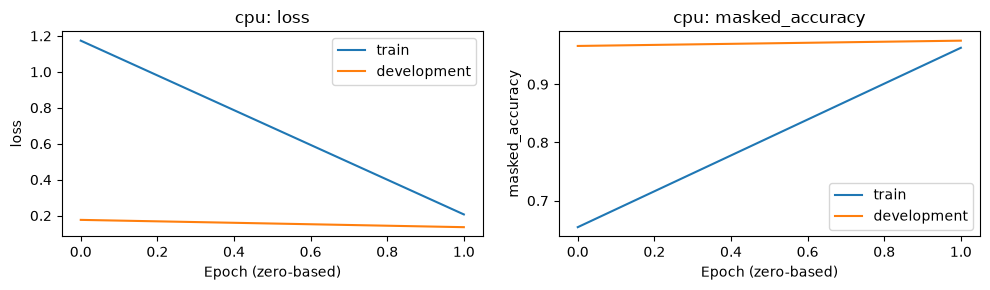

In [6]:
def load_bundle(directory):
    directory = Path(directory)
    saved = json.loads((directory / 'metadata.json').read_text(encoding='utf-8'))
    tokens = saved['tokens']
    normalization = saved['normalization']
    if saved['format_version'] != 1 or tokens[:3] != ['<pad>', '<bos>', '<eos>']:
        raise ValueError('Unsupported bundle format or special-token IDs')
    if len(set(tokens)) != len(tokens) or any(len(t) != 1 for t in tokens[3:]):
        raise ValueError('Invalid saved character vocabulary')
    if normalization != dict(space_token=SPACE, unsupported_token='#', max_chars=MODEL_MAX_CHARS):
        raise ValueError('Bundle normalization is incompatible with this notebook')
    if not {SPACE, '#'} <= set(tokens) or saved['model_config']['vocab_size'] != len(tokens):
        raise ValueError('Bundle vocabulary/configuration mismatch')
    if saved['model_config']['max_chars'] != MODEL_MAX_CHARS:
        raise ValueError('Bundle length limit is incompatible with this notebook')
    restored = SpellTransformer(**saved['model_config'])
    restored((tf.constant([[BOS, EOS]]), tf.constant([[BOS]])))
    restored.load_weights(directory / 'best.weights.h5')
    return restored, saved


inference_model, saved_metadata = load_bundle(OUTPUT_DIR)
print('Loaded checkpoint:', {k: v for k, v in saved_metadata['training'].items() if k != 'validation_indices'})
saved_history = json.loads((OUTPUT_DIR / 'history.json').read_text(encoding='utf-8'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, name in zip(axes, ['loss', 'masked_accuracy']):
    ax.plot(saved_history[name], label='train')
    ax.plot(saved_history['val_' + name], label='development')
    ax.set(xlabel='Epoch (zero-based)', ylabel=name, title=MODE + ': ' + name)
    ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150)
plt.show()


## 4. Autoregressive correction and evaluation
Greedy decoding starts at BOS, excludes PAD/BOS from generated content, and stops at EOS. Missing EOS raises `GenerationError`; it is never disguised as a successful truncated correction. Generation for an input of length *n* may produce at most `min(limit, n + 50)` characters (the corpus never adds more than 43 characters to a source). Smoke mode deliberately caps generated content at 32 characters to bound validation work; CPU mode allows 128 and full mode 512. The decoder makes one additional decision to allow EOS immediately after the last permitted character.

Evaluation uses normalized corpus characters (displaying the whitespace marker as a space). Exact match counts failed decoding as incorrect and reports the failure count/rate. Corpus character error rate (sum of Levenshtein distances divided by sum of reference lengths) is reported only if every example terminates; otherwise it is `None`, not a biased success-only score. A second, always-defined CER counts every failed decode as an empty output, so failures are fully penalized rather than ignored. Unchanged preservation and changed-example exact match expose overcorrection and copying. An absent subgroup is reported as `None` with its count of zero.

Smoke evaluation deterministically selects up to two short changed and two short unchanged examples from development, reporting the actual counts. It is a deliberately stratified workflow check, **not** a representative quality estimate. CPU evaluation uses a seeded 4,000-pair sample of the development pairs within 128 characters that were **not** in the 2,000-pair checkpoint-selection subset, so it is held out from model selection (but still covers only in-range lengths). Full evaluation uses every development pair, including long examples.

Evaluation decodes inputs in length-sorted batches with the encoder computed once per batch. This is an efficiency change only: greedy choices, stopping rules and limits are identical to single-input decoding, and a check below compares both paths on real development inputs. Saved indices refer to the validated split after blank filtering, not original file line numbers. Per-example failures retain the error message and a null prediction; they are never replaced with copied inputs.

In [7]:
class GenerationError(RuntimeError):
    pass


def greedy_decode(predictor, source_ids, vocab_size, max_chars=MODEL_MAX_CHARS):
    if not 1 <= max_chars <= MODEL_MAX_CHARS:
        raise ValueError(f'max_chars must be between 1 and {MODEL_MAX_CHARS}')
    generated = [BOS]
    source = tf.constant([source_ids], dtype=tf.int32)
    for _ in range(max_chars + 1):
        logits = predictor((source, tf.constant([generated], dtype=tf.int32)), training=False)
        scores = np.array(logits[0, -1], dtype=np.float64, copy=True)
        if scores.shape != (vocab_size,) or not np.all(np.isfinite(scores)):
            raise GenerationError('Invalid or non-finite decoder logits')
        scores[[PAD, BOS]] = -np.inf
        next_id = int(np.argmax(scores))
        if next_id == EOS:
            return generated[1:]
        if len(generated) - 1 == max_chars:
            break
        generated.append(next_id)
    raise GenerationError(f'Decoder did not emit EOS within {max_chars} content characters')


def batch_greedy_decode(predictor, source_batch, vocab_size, limits):
    """Greedy-decode several inputs at once; returns (token_ids, None) or (None, error) per input."""
    if not source_batch or len(source_batch) != len(limits):
        raise ValueError('Batch decoding requires aligned, nonempty sources and limits')
    if any(not 1 <= limit <= MODEL_MAX_CHARS for limit in limits):
        raise ValueError(f'Decode limits must be between 1 and {MODEL_MAX_CHARS}')
    rows, width = len(source_batch), max(map(len, source_batch))
    source = tf.constant([ids + [PAD] * (width - len(ids)) for ids in source_batch], dtype=tf.int32)
    generated = np.full((rows, max(limits) + 1), PAD, dtype=np.int32)
    generated[:, 0] = BOS
    lengths, active = np.zeros(rows, dtype=int), np.ones(rows, dtype=bool)
    results = [None] * rows
    for step in range(max(limits) + 1):
        logits = predictor((source, tf.constant(generated[:, :step + 1])), training=False)
        scores = np.array(logits[:, -1, :], dtype=np.float64, copy=True)
        if scores.shape != (rows, vocab_size):
            raise GenerationError('Invalid decoder logits shape')
        for i in np.flatnonzero(active):
            if not np.all(np.isfinite(scores[i])):
                results[i], active[i] = (None, 'Invalid or non-finite decoder logits'), False
                continue
            scores[i, [PAD, BOS]] = -np.inf
            next_id = int(np.argmax(scores[i]))
            if next_id == EOS:
                results[i], active[i] = (generated[i, 1:lengths[i] + 1].tolist(), None), False
            elif lengths[i] == limits[i]:
                results[i] = (None, f'Decoder did not emit EOS within {limits[i]} content characters')
                active[i] = False
            else:
                lengths[i] += 1
                generated[i, lengths[i]] = next_id
        if not active.any():
            break
    return results


class CompiledPredictor:
    """Compiled inference that encodes each source batch once and reruns only the decoder per step."""

    def __init__(self, model):
        @tf.function(reduce_retracing=True)
        def encode(source):
            return model.encode(source, training=False)

        @tf.function(reduce_retracing=True)
        def decode_last(source, encoded, target):
            return model.decode(source, encoded, target, training=False)[:, -1:, :]

        self._encode, self._decode_last = encode, decode_last
        self._source, self._encoded = None, None

    def __call__(self, inputs, training=False):
        source, target = inputs
        if source is not self._source:
            self._source, self._encoded = source, self._encode(source)
        return self._decode_last(source, self._encoded, target)


class SpellChecker:
    def __init__(self, predictor, bundle_metadata, max_decode_chars=MODEL_MAX_CHARS, decode_margin=DECODE_MARGIN):
        self.predictor = predictor
        self.tokens = bundle_metadata['tokens']
        self.lookup = {token: i for i, token in enumerate(self.tokens)}
        self.max_decode_chars = max_decode_chars
        self.decode_margin = decode_margin

    def _prepare(self, text):
        normalized = normalize_raw(text, self.lookup)
        limit = min(self.max_decode_chars, len(normalized) + self.decode_margin)
        return [BOS] + [self.lookup[c] for c in normalized] + [EOS], limit

    def _result(self, text, result_ids):
        corrected = ''.join(self.tokens[i] for i in result_ids).replace(SPACE, ' ')
        return dict(corrected_text=corrected, changed=corrected != text)

    def correct(self, text):
        source_ids, limit = self._prepare(text)
        if text == '':
            return dict(corrected_text='', changed=False)
        return self._result(text, greedy_decode(self.predictor, source_ids, len(self.tokens), limit))

    def correct_batch(self, texts, batch_size=64, progress_every=None):
        """Correct many texts; returns (result, None) or (None, generation_error) per text, in input order."""
        prepared = [self._prepare(text) for text in texts]
        outcomes = [(dict(corrected_text='', changed=False), None) if text == '' else None for text in texts]
        pending = sorted((i for i, text in enumerate(texts) if text != ''), key=lambda i: len(prepared[i][0]))
        started = time.perf_counter()
        for batch_number, start in enumerate(range(0, len(pending), batch_size), 1):
            chunk = pending[start:start + batch_size]
            decoded = batch_greedy_decode(self.predictor, [prepared[i][0] for i in chunk], len(self.tokens),
                                          [prepared[i][1] for i in chunk])
            for i, (result_ids, error) in zip(chunk, decoded):
                outcomes[i] = (None, error) if error else (self._result(texts[i], result_ids), None)
            if progress_every and (batch_number % progress_every == 0 or start + batch_size >= len(pending)):
                print(f'Decoded {min(start + batch_size, len(pending))}/{len(pending)} inputs '
                      f'in {time.perf_counter() - started:.0f}s')
        return outcomes


def correction_metrics(sources, references, predictions):
    if not sources or not len(sources) == len(references) == len(predictions):
        raise ValueError('Metrics require nonempty, aligned sources/references/predictions')
    unchanged = [i for i, (s, r) in enumerate(zip(sources, references)) if s == r]
    changed = [i for i, (s, r) in enumerate(zip(sources, references)) if s != r]
    exact = [p == r for p, r in zip(predictions, references)]
    failures = sum(p is None for p in predictions)
    reference_chars = sum(map(len, references))
    cer = (sum(edit_distance(p, r) for p, r in zip(predictions, references)) / reference_chars
           if not failures and reference_chars else None)
    conservative_cer = (sum(edit_distance(p if p is not None else '', r) for p, r in zip(predictions, references))
                        / reference_chars if reference_chars else None)
    return dict(examples=len(sources), unchanged_examples=len(unchanged), changed_examples=len(changed),
                reference_characters=reference_chars, decode_failures=failures,
                decode_failure_rate=failures / len(sources), exact_match=sum(exact) / len(exact),
                character_error_rate=cer, character_error_rate_failures_as_empty=conservative_cer,
                unchanged_preservation=sum(exact[i] for i in unchanged) / len(unchanged) if unchanged else None,
                changed_exact_match=sum(exact[i] for i in changed) / len(changed) if changed else None)


def evaluation_indices(pairs, mode, excluded=()):
    if mode == 'full':
        return list(range(len(pairs)))
    if mode == 'cpu':
        excluded = set(excluded)
        held_out = [i for i, pair in enumerate(pairs) if within_model_length(pair) and i not in excluded]
        count = min(CPU_EVALUATION_PAIRS, len(held_out))
        return sorted(np.random.default_rng(SEED + 1).choice(held_out, count, replace=False).tolist())
    if mode != 'smoke':
        raise ValueError('Evaluation mode must be smoke, cpu or full')
    selected = []
    for unchanged in [False, True]:
        group = [i for i, (s, t) in enumerate(pairs) if (s == t) == unchanged and max(len(s), len(t)) <= 80]
        selected.extend(group[:2])
    if not selected:
        raise ValueError('No short examples available for smoke evaluation')
    return sorted(selected)


evaluation_mode = saved_metadata['training']['mode']
if evaluation_mode != MODE:
    raise ValueError('Loaded bundle mode differs from MODE; select the matching bundle before evaluating')
checker = SpellChecker(inference_model, saved_metadata, max_decode_chars=DECODE_LIMIT)
batch_checker = SpellChecker(CompiledPredictor(inference_model), saved_metadata, max_decode_chars=DECODE_LIMIT)
selected_indices = evaluation_indices(dev_pairs, evaluation_mode, saved_metadata['training'].get('validation_indices') or ())
evaluation_pairs = [dev_pairs[i] for i in selected_indices]
sources = [display_content(s) for s, _ in evaluation_pairs]
references = [display_content(t) for _, t in evaluation_pairs]
started = time.perf_counter()
outcomes = batch_checker.correct_batch(sources, batch_size=64, progress_every=20)
evaluation_seconds = time.perf_counter() - started
predictions, prediction_records = [], []
for index, (source, reference, (result, error_message)) in enumerate(zip(sources, references, outcomes)):
    prediction = None if result is None else result['corrected_text']
    predictions.append(prediction)
    prediction_records.append(dict(development_index=selected_indices[index], source=source, reference=reference,
                                   prediction=prediction, generation_error=error_message,
                                   exact_match=prediction == reference, unchanged_input=source == reference,
                                   edit_distance=edit_distance(prediction, reference) if prediction is not None else None))
failed_records = [record for record in prediction_records if record['generation_error']]
for record in failed_records[:5]:
    print(f"Development index {record['development_index']}: {record['generation_error']}")
if len(failed_records) > 5:
    print(f'... and {len(failed_records) - 5} more decoding failures')
expected_count = len(dev_pairs) if evaluation_mode == 'full' else len(selected_indices)
assert len(prediction_records) == expected_count
split_labels = dict(smoke='stratified development smoke subset',
                    cpu=f'seeded sample of development pairs up to {MODEL_MAX_CHARS} characters, excluding the checkpoint-selection subset',
                    full='development')
selection_labels = dict(smoke='up to two short examples per subgroup',
                        cpu=f'seeded {CPU_EVALUATION_PAIRS}-pair sample of in-range development pairs not used for checkpoint selection',
                        full='all')
evaluation = dict(mode=evaluation_mode, split=split_labels[evaluation_mode],
                  available_development_examples=len(dev_pairs), expected_evaluated_examples=expected_count,
                  decode_limit=DECODE_LIMIT, decode_margin=DECODE_MARGIN, selection=selection_labels[evaluation_mode],
                  held_out_from_checkpoint_selection=evaluation_mode == 'cpu',
                  evaluation_seconds=round(evaluation_seconds, 1),
                  checkpoint_best_validation_loss=saved_metadata['training']['best_validation_loss'],
                  model=correction_metrics(sources, references, predictions),
                  copy_baseline=correction_metrics(sources, references, sources))
print(json.dumps(evaluation, indent=2))
(OUTPUT_DIR / 'evaluation.json').write_text(json.dumps(evaluation, indent=2), encoding='utf-8')
with (OUTPUT_DIR / 'predictions.jsonl').open('w', encoding='utf-8') as output:
    for record in prediction_records:
        output.write(json.dumps(record, ensure_ascii=True) + '\n')
for example in ['Ths is a smple sentnce.', 'I recieve teh files tomorow.', 'This is already correct.', '']:
    try:
        print(repr(example), '->', checker.correct(example))
    except GenerationError as error:
        print(repr(example), '-> GENERATION FAILED:', error)


C:\Users\nizare\.copilot\runtimes\spellcheck574\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis 3 of a tensor of shape (64, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Decoded 1280/4000 inputs in 34s


Decoded 2560/4000 inputs in 125s


Decoded 3840/4000 inputs in 295s


Decoded 4000/4000 inputs in 341s


Development index 10882: Decoder did not emit EOS within 128 content characters


{
  "mode": "cpu",
  "split": "seeded sample of development pairs up to 128 characters, excluding the checkpoint-selection subset",
  "available_development_examples": 12752,
  "expected_evaluated_examples": 4000,
  "decode_limit": 128,
  "decode_margin": 50,
  "selection": "seeded 4000-pair sample of in-range development pairs not used for checkpoint selection",
  "held_out_from_checkpoint_selection": true,
  "evaluation_seconds": 340.8,
  "checkpoint_best_validation_loss": 0.13556241989135742,
  "model": {
    "examples": 4000,
    "unchanged_examples": 160,
    "changed_examples": 3840,
    "reference_characters": 243777,
    "decode_failures": 1,
    "decode_failure_rate": 0.00025,
    "exact_match": 0.12975,
    "character_error_rate": null,
    "character_error_rate_failures_as_empty": 0.028862443954926018,
    "unchanged_preservation": 0.875,
    "changed_exact_match": 0.09869791666666666
  },
  "copy_baseline": {
    "examples": 4000,
    "unchanged_examples": 160,
    "changed

'Ths is a smple sentnce.' -> {'corrected_text': 'This a smple sentnce.', 'changed': True}


'I recieve teh files tomorow.' -> {'corrected_text': 'I receive teh files tomorow.', 'changed': True}


'This is already correct.' -> {'corrected_text': 'This is already correct.', 'changed': False}
'' -> {'corrected_text': '', 'changed': False}


## Evaluation and interpretation (rubric: 20 points)
All scores and examples below come from the current run. Differences are **model minus copy baseline**, in absolute metric units, not relative improvement percentages. Higher exact match/preservation is better; lower CER/failure rate is better. A missing value is `N/A`, not zero. The example groups are descriptive output categories, not linguistic error diagnoses, and show at most three examples each in development-index order.

A successful correction exactly matches a changed reference. A missed/incorrect correction is a terminated, nonexact output for a changed reference. An overcorrection is a terminated output that alters an already-correct input. Failed decoding is listed separately, never counted as successful preservation. These are observed outcomes; attributing their causes requires further experiments.

In [8]:
def metric_delta(model_score, baseline_score):
    return None if model_score is None or baseline_score is None else model_score - baseline_score


def result_category(record):
    if record['prediction'] is None:
        return 'Decoding failures'
    if record['unchanged_input']:
        return 'Unchanged inputs preserved' if record['exact_match'] else 'Overcorrections'
    return 'Successful corrections' if record['exact_match'] else 'Missed/incorrect corrections'


def interpret_results(result):
    measured, baseline = result['model'], result['copy_baseline']
    statements = [f"Evaluated {measured['examples']} of {result['available_development_examples']} development pairs ({result['split']})."]
    if result['mode'] == 'smoke':
        statements.append('SMOKE ONLY: this subset and reduced model do not establish full-training correction quality.')
    elif result['mode'] == 'cpu':
        statements.append(f'Reduced CPU experiment: trained on pairs up to {MODEL_MAX_CHARS} characters and evaluated on '
                          'development pairs held out from checkpoint selection; results do not cover longer inputs '
                          'or the larger full-mode model.')
    else:
        statements.append('Full-mode results describe this checkpoint on development data, not an unseen test set.')
    delta = metric_delta(measured['exact_match'], baseline['exact_match'])
    if delta > 0:
        statements.append(f'Observed exact match exceeds copying by {delta:.4f} absolute units on this evaluated set.')
    elif delta < 0:
        statements.append(f'Observed exact match is below copying by {-delta:.4f} absolute units on this evaluated set.')
    else:
        statements.append('Observed exact match does not exceed copying; both scores are equal.')
    statements.append(f"Decoding failed for {measured['decode_failures']}/{measured['examples']} inputs ({measured['decode_failure_rate']:.1%}).")
    if measured['character_error_rate'] is None:
        statements.append('Overall model CER is unavailable; no success-only CER is substituted.')
        if measured.get('character_error_rate_failures_as_empty') is not None:
            statements.append(f"Counting each failed decode as an empty output (fully penalized), model CER is "
                              f"{measured['character_error_rate_failures_as_empty']:.4f} versus "
                              f"{baseline['character_error_rate_failures_as_empty']:.4f} for copying.")
    else:
        statements.append(f"Model CER is {measured['character_error_rate']:.4f}; copy CER is {baseline['character_error_rate']:.4f}.")
    if measured['unchanged_examples']:
        statements.append(f"Preserved {measured['unchanged_preservation']:.1%} of {measured['unchanged_examples']} unchanged inputs; failures also count against preservation.")
    else:
        statements.append('No unchanged examples were evaluated; preservation cannot be assessed.')
    if measured['changed_examples']:
        statements.append(f"Exactly corrected {measured['changed_exact_match']:.1%} of {measured['changed_examples']} changed inputs.")
    else:
        statements.append('No changed examples were evaluated; correction success cannot be assessed.')
    statements.append('Teacher-forced accuracy and falling loss alone do not prove autoregressive correction. Inspect termination and example evidence before attributing causes.')
    if result['mode'] == 'cpu':
        statements.append('A separate development subset selected the checkpoint. Domain bias and irreversible # normalization still limit generalization claims.')
    else:
        statements.append('Development data selected the checkpoint. Domain bias and irreversible # normalization limit generalization claims.')
    return statements


display(Markdown(f"### Current evidence: {evaluation['mode']} / {evaluation['split']}"))
show_table(['Evaluated', 'Available development', 'Changed', 'Unchanged', 'Decode content limit'],
           [[evaluation['model']['examples'], evaluation['available_development_examples'],
             evaluation['model']['changed_examples'], evaluation['model']['unchanged_examples'], evaluation['decode_limit']]])
comparison_metrics = [('exact_match', 'Higher'), ('character_error_rate', 'Lower'),
                      ('character_error_rate_failures_as_empty', 'Lower'),
                      ('unchanged_preservation', 'Higher'), ('changed_exact_match', 'Higher'),
                      ('decode_failure_rate', 'Lower')]
def format_score(value):
    return 'N/A' if value is None else f'{value:.4f}'


comparison_rows = []
for metric, direction in comparison_metrics:
    measured, baseline = evaluation['model'][metric], evaluation['copy_baseline'][metric]
    comparison_rows.append([metric, direction, format_score(measured), format_score(baseline),
                            format_score(metric_delta(measured, baseline))])
show_table(['Metric', 'Better', 'Model', 'Copy baseline', 'Model minus copy'], comparison_rows)
for category in ['Successful corrections', 'Missed/incorrect corrections', 'Unchanged inputs preserved',
                 'Overcorrections', 'Decoding failures']:
    group = [record for record in prediction_records if result_category(record) == category]
    display(Markdown(f'### {category} ({len(group)} observed)'))
    if not group:
        display(Markdown('No observed examples in this evaluated set.'))
    else:
        show_table(['Dev index', 'Input', 'Expected', 'Prediction', 'Failure'],
                   [[r['development_index'], repr(r['source']), repr(r['reference']),
                     repr(r['prediction']), r['generation_error'] or '-'] for r in group[:3]])
display(Markdown('### Evidence-based conclusion\n' + '\n'.join('- ' + s for s in interpret_results(evaluation))))
experiment_note = dict(
    smoke='Smoke mode tests the pipeline only; it is not a trained spell-checker.',
    cpu=f"CPU mode is a genuine but reduced experiment (inputs up to {MODEL_MAX_CHARS} characters, "
        f"{CONFIG['num_layers']} blocks per side); full mode on a GPU remains the larger-scale option.",
    full='These results come from the configured full-scale run.')[evaluation['mode']]
display(Markdown('**Implementation vs. experiment:** the checks below test code behavior. ' + experiment_note))


### Current evidence: cpu / seeded sample of development pairs up to 128 characters, excluding the checkpoint-selection subset

| Evaluated | Available development | Changed | Unchanged | Decode content limit |
| --- | --- | --- | --- | --- |
| 4000 | 12752 | 3840 | 160 | 128 |

| Metric | Better | Model | Copy baseline | Model minus copy |
| --- | --- | --- | --- | --- |
| exact_match | Higher | 0.1298 | 0.0400 | 0.0897 |
| character_error_rate | Lower | N/A | 0.0292 | N/A |
| character_error_rate_failures_as_empty | Lower | 0.0289 | 0.0292 | -0.0003 |
| unchanged_preservation | Higher | 0.8750 | 1.0000 | -0.1250 |
| changed_exact_match | Higher | 0.0987 | 0.0000 | 0.0987 |
| decode_failure_rate | Lower | 0.0003 | 0.0000 | 0.0003 |

### Successful corrections (379 observed)

| Dev index | Input | Expected | Prediction | Failure |
| --- | --- | --- | --- | --- |
| 18 | '### Four Categories of Accessibilitiy' | '### Four Categories of Accessibility' | '### Four Categories of Accessibility' | - |
| 21 | '#### Aditional links' | '#### Additional links' | '#### Additional links' | - |
| 80 | 'using DataStrcutres#' | 'using DataStructures#' | 'using DataStructures#' | - |

...

| Dev index | Input | Expected | Prediction | Failure |
| --- | --- | --- | --- | --- |
| 459 | '########################' | '########################' | '#######################' | - |
| 1746 | '- #hasOmnibar# #mdash# ##Optional.## Indicates whether the viewkeeper leaves space for an omnibar. ##Default # #true###' | '- #hasOmnibar# #mdash# ##Optional.## Indicates whether the viewkeeper leaves space for an omnibar. ##Default # #true###' | '- #hasOmnibar# #mdash# ##Optional.## Indicates whether the viewkeeper leaves space for an omnibar. ##Default # #true##' | - |
| 2785 | '## Copyright #c# 2011 Google, Inc.' | '## Copyright #c# 2011 Google, Inc.' | '## Copyright #c# 2011 Googgle, Inc.' | - |

### Decoding failures (1 observed)

| Dev index | Input | Expected | Prediction | Failure |
| --- | --- | --- | --- | --- |
| 10882 | 'moto 1.0.X mock docorators are defined for boto3 and do not work with boto2. Use the #mock#AWSSVC#deprecated to work with boto2.' | 'moto 1.0.X mock decorators are defined for boto3 and do not work with boto2. Use the #mock#AWSSVC#deprecated to work with boto2.' | None | Decoder did not emit EOS within 128 content characters |

### Evidence-based conclusion
- Evaluated 4000 of 12752 development pairs (seeded sample of development pairs up to 128 characters, excluding the checkpoint-selection subset).
- Reduced CPU experiment: trained on pairs up to 128 characters and evaluated on development pairs held out from checkpoint selection; results do not cover longer inputs or the larger full-mode model.
- Observed exact match exceeds copying by 0.0897 absolute units on this evaluated set.
- Decoding failed for 1/4000 inputs (0.0%).
- Overall model CER is unavailable; no success-only CER is substituted.
- Counting each failed decode as an empty output (fully penalized), model CER is 0.0289 versus 0.0292 for copying.
- Preserved 87.5% of 160 unchanged inputs; failures also count against preservation.
- Exactly corrected 9.9% of 3840 changed inputs.
- Teacher-forced accuracy and falling loss alone do not prove autoregressive correction. Inspect termination and example evidence before attributing causes.
- A separate development subset selected the checkpoint. Domain bias and irreversible # normalization still limit generalization claims.

**Implementation vs. experiment:** the checks below test code behavior. CPU mode is a genuine but reduced experiment (inputs up to 128 characters, 2 blocks per side); full mode on a GPU remains the larger-scale option.

## 5. Focused correctness checks
These assertions verify implementation behavior, **not learned spelling quality**. They cover corpus alignment and blanks, exact length boundaries, normalization, target shifts, causal/padding masks and output invariance, masked metrics, finite gradients and a real weight update on a separate probe model, checkpoint reload consistency, bounded deterministic decoding and output shape, batched decoding (including agreement with single-input decoding on real development inputs), the CPU evaluation/validation split, and hand-computable evaluation metrics. Deterministic fixtures test inference edge cases without expecting a smoke-trained model to spell correctly.

For full training, inspect saved curves and autoregressive metrics, compare the copy baseline, and inspect representative successes and failures. A high teacher-forced token accuracy can still reflect copying frequent characters rather than correcting errors.

In [9]:
def expect_error(error_type, function, *args):
    try:
        function(*args)
    except error_type:
        return
    raise AssertionError(f'Expected {error_type.__name__}')


assert display_content(normalize_raw(' A  b ')) == ' A  b '
assert display_content(normalize_raw('a\tb\nc')) == 'a b c'
assert normalize_raw('a_\u00e9') == 'a##'
assert len(encode_content(normalize_raw('a' * MODEL_MAX_CHARS))) == MODEL_MAX_CHARS
expect_error(ValueError, normalize_raw, 'a' * (MODEL_MAX_CHARS + 1))
expect_error(TypeError, normalize_raw, None)
with tempfile.TemporaryDirectory() as directory:
    a, b = Path(directory) / 'source.txt', Path(directory) / 'target.txt'
    a.write_text('\na\n', encoding='utf-8')
    b.write_text('\nb\n', encoding='utf-8')
    pairs, stats = read_pairs(a, b)
    assert pairs == [('a', 'b')] and stats['paired_blanks_skipped'] == 1
    a.write_text('a\na\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    b.write_text('b\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    a.write_text('aa\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    a.write_text('@\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)
    a.write_text(' '.join('a' * 513) + '\n', encoding='utf-8')
    expect_error(ValueError, read_pairs, a, b)

(source_batch, decoder_batch), target_batch = next(iter(make_dataset(training_pairs[:2])))
target_ids = encode_content(training_pairs[0][1])
assert decoder_batch[0, :len(target_ids) + 1].numpy().tolist() == [BOS] + target_ids
assert target_batch[0, :len(target_ids) + 1].numpy().tolist() == target_ids + [EOS]
assert source_batch[0, 0] == BOS
long_ids = tf.constant([[BOS] + encode_content('a' * MODEL_MAX_CHARS) + [EOS]])
assert inference_model((long_ids, long_ids[:, :-1])).shape == (1, MODEL_MAX_CHARS + 1, len(id_to_token))
assert all(within_model_length(pair) for pair in training_pairs)

src = tf.constant([[BOS, token_to_id['a'], EOS, PAD]])
tgt = tf.constant([[BOS, token_to_id['a'], token_to_id['b'], PAD]])
sm, tm, cm = attention_masks(src, tgt)
assert not np.any(sm.numpy()[:, :, -1]) and not np.any(sm.numpy()[:, -1, :])
assert not np.any(np.triu(tm.numpy()[0], 1))
assert not np.any(cm.numpy()[:, :, -1]) and not np.any(cm.numpy()[:, -1, :])
original = inference_model((src, tgt), training=False).numpy()
changed_future = tf.constant([[BOS, token_to_id['c'], token_to_id['d'], PAD]])
np.testing.assert_allclose(original[:, :1], inference_model((src, changed_future))[:, :1], atol=1e-5)
padded = inference_model((tf.pad(src, [[0, 0], [0, 2]]), tf.pad(tgt, [[0, 0], [0, 2]])))
np.testing.assert_allclose(original[:, :3], padded[:, :3], atol=1e-5)

labels = tf.constant([[3, EOS]])
logits = tf.one_hot(labels, len(id_to_token), on_value=4.0, off_value=0.0)
padded_labels = tf.pad(labels, [[0, 0], [0, 3]])
padded_logits = tf.pad(logits, [[0, 0], [0, 3], [0, 0]])
np.testing.assert_allclose(masked_loss(labels, logits), masked_loss(padded_labels, padded_logits), atol=1e-7)
accuracy = MaskedAccuracy()
accuracy.update_state(padded_labels, padded_logits)
assert float(accuracy.result()) == 1.0 and float(accuracy.total) == 2.0
accuracy.reset_state()
assert float(accuracy.total) == 0.0

probe_config = dict(CONFIG, d_model=16, num_heads=2, ff_dim=32, num_layers=1, dropout=0.0)
probe = SpellTransformer(**probe_config)
probe_inputs, probe_labels = next(iter(make_dataset(training_pairs[:2])))
with tf.GradientTape() as tape:
    loss = masked_loss(probe_labels, probe(probe_inputs, training=True))
gradients = tape.gradient(loss, probe.trainable_variables)
assert np.isfinite(float(loss)) and all(g is not None for g in gradients)
for gradient in gradients:
    tf.debugging.assert_all_finite(tf.convert_to_tensor(gradient), 'Non-finite gradient')
before = [v.numpy().copy() for v in probe.trainable_variables]
tf.keras.optimizers.Adam(1e-3).apply_gradients(zip(gradients, probe.trainable_variables))
assert any(not np.array_equal(a, b.numpy()) for a, b in zip(before, probe.trainable_variables))
np.testing.assert_allclose(model(batch_inputs, training=False), inference_model(batch_inputs, training=False),
                           rtol=1e-5, atol=1e-5)
np.testing.assert_array_equal(tf.argmax(model(batch_inputs), -1), tf.argmax(inference_model(batch_inputs), -1))


class FixedDecoder:
    def __init__(self, output_ids):
        self.output_ids = output_ids

    def __call__(self, inputs, training=False):
        _, target = inputs
        index = int(tf.shape(target)[1]) - 1
        token = self.output_ids[min(index, len(self.output_ids) - 1)]
        scores = tf.one_hot(token, len(id_to_token), on_value=5.0, off_value=-5.0)
        return tf.broadcast_to(scores, [1, tf.shape(target)[1], len(id_to_token)])


fixture = SpellChecker(FixedDecoder([token_to_id['a'], EOS]), saved_metadata)
assert fixture.correct('a') == dict(corrected_text='a', changed=False)
assert fixture.correct('b') == dict(corrected_text='a', changed=True)
assert fixture.correct('') == dict(corrected_text='', changed=False)
expect_error(ValueError, fixture.correct, 'a' * (MODEL_MAX_CHARS + 1))
expect_error(TypeError, fixture.correct, None)
assert SpellChecker(FixedDecoder([EOS]), saved_metadata).correct('a')['corrected_text'] == ''
assert greedy_decode(FixedDecoder([token_to_id['a'], EOS]), [BOS, EOS], len(id_to_token), 1) == [token_to_id['a']]
expect_error(GenerationError, greedy_decode, FixedDecoder([token_to_id['a']]), [BOS, EOS], len(id_to_token), 1)


class SpecialTokenDecoder:
    def __call__(self, inputs, training=False):
        _, target = inputs
        scores = tf.constant([100.0, 99.0, 98.0] + [-5.0] * (len(id_to_token) - 3))
        return tf.broadcast_to(scores, [1, tf.shape(target)[1], len(id_to_token)])


assert greedy_decode(SpecialTokenDecoder(), [BOS, EOS], len(id_to_token), 1) == []
max_length_fixture = FixedDecoder([token_to_id['a']] * MODEL_MAX_CHARS + [EOS])
assert len(greedy_decode(max_length_fixture, [BOS, EOS], len(id_to_token))) == MODEL_MAX_CHARS


class BatchFixedDecoder:
    def __init__(self, rows):
        self.rows = rows

    def __call__(self, inputs, training=False):
        _, target = inputs
        batch, step = int(tf.shape(target)[0]), int(tf.shape(target)[1]) - 1
        rows = self.rows if len(self.rows) > 1 else self.rows * batch
        tokens = [row[min(step, len(row) - 1)] for row in rows]
        scores = tf.one_hot(tokens, len(id_to_token), on_value=5.0, off_value=-5.0)
        return tf.repeat(scores[:, None, :], tf.shape(target)[1], axis=1)


a_id, b_id = token_to_id['a'], token_to_id['b']
batch_outcomes = batch_greedy_decode(BatchFixedDecoder([[a_id, EOS], [b_id, b_id, EOS], [a_id]]),
                                     [[BOS, EOS], [BOS, a_id, EOS], [BOS, EOS]], len(id_to_token), [3, 3, 2])
assert batch_outcomes[0] == ([a_id], None) and batch_outcomes[1] == ([b_id, b_id], None)
assert batch_outcomes[2][0] is None and 'within 2' in batch_outcomes[2][1]
assert batch_greedy_decode(SpecialTokenDecoder(), [[BOS, EOS]], len(id_to_token), [1]) == [([], None)]
expect_error(ValueError, batch_greedy_decode, BatchFixedDecoder([[EOS]]), [[BOS, EOS]], len(id_to_token),
             [MODEL_MAX_CHARS + 1])
expect_error(ValueError, batch_greedy_decode, BatchFixedDecoder([[EOS]]), [], len(id_to_token), [])
assert SpellChecker(BatchFixedDecoder([[a_id, EOS]]), saved_metadata).correct_batch(['b', '', 'a']) == [
    (dict(corrected_text='a', changed=True), None), (dict(corrected_text='', changed=False), None),
    (dict(corrected_text='a', changed=False), None)]
assert SpellChecker(FixedDecoder([a_id, a_id, EOS]), saved_metadata, decode_margin=1).correct('a') == dict(
    corrected_text='aa', changed=True)
expect_error(GenerationError, SpellChecker(FixedDecoder([a_id, a_id, a_id, EOS]), saved_metadata,
                                           decode_margin=1).correct, 'a')
consistency_texts = sorted(sources, key=len)[:4]
for text, (batched, batched_error) in zip(consistency_texts, batch_checker.correct_batch(consistency_texts)):
    try:
        single, single_error = checker.correct(text), None
    except GenerationError as error:
        single, single_error = None, str(error)
    assert batched == single and batched_error == single_error, (text, batched, single)
normalized_fixture = SpellChecker(FixedDecoder([token_to_id['#'], EOS]), saved_metadata)
assert normalized_fixture.correct('\u00e9') == dict(corrected_text='#', changed=True)
assert edit_distance('kitten', 'sitting') == 3 and edit_distance('', 'abc') == 3
score = correction_metrics(['ab', 'ax'], ['ab', 'ay'], ['ab', 'ax'])
assert score['exact_match'] == 0.5 and score['character_error_rate'] == 0.25
assert score['unchanged_preservation'] == 1.0 and score['changed_exact_match'] == 0.0
failed = correction_metrics(['ab'], ['ab'], [None])
assert failed['decode_failures'] == 1 and failed['exact_match'] == 0 and failed['character_error_rate'] is None
assert failed['character_error_rate_failures_as_empty'] == 1.0
assert score['character_error_rate_failures_as_empty'] == score['character_error_rate']
expect_error(ValueError, correction_metrics, [], [], [])

# Reporting fixtures are independent of the smoke-trained model's quality.
assert sample_indices(20, 5) == sample_indices(20, 5)
assert sample_indices(3, 20) == [0, 1, 2] and sample_indices(0, 2) == []
expect_error(ValueError, sample_indices, 3, -1)
assert evaluation_indices(dev_pairs, 'full') == list(range(len(dev_pairs)))
assert evaluation_indices(dev_pairs, 'smoke') == evaluation_indices(dev_pairs, 'smoke')
smoke_indices = evaluation_indices(dev_pairs, 'smoke')
assert sum(dev_pairs[i][0] == dev_pairs[i][1] for i in smoke_indices) == 2
assert sum(dev_pairs[i][0] != dev_pairs[i][1] for i in smoke_indices) == 2
expect_error(ValueError, evaluation_indices, dev_pairs, 'invalid')
if MODE == 'cpu':
    cpu_indices = evaluation_indices(dev_pairs, 'cpu', validation_indices)
    assert cpu_indices == selected_indices and not set(cpu_indices) & set(validation_indices)
    assert all(within_model_length(dev_pairs[i]) for i in cpu_indices + validation_indices)
    held_out_count = sum(map(within_model_length, dev_pairs)) - len(validation_indices)
    assert len(cpu_indices) == len(set(cpu_indices)) == min(CPU_EVALUATION_PAIRS, held_out_count)
    assert cpu_indices == evaluation_indices(dev_pairs, 'cpu', validation_indices)
for name, pairs in [('training', train_pairs), ('development', dev_pairs)]:
    summary = exploration[name]
    assert summary['unchanged'] + summary['changed'] == summary['usable_pairs'] == len(pairs)
    assert summary['distance_sample_indices'] == sample_indices(len(pairs), 256)
    assert summary['distance_sample_size'] == min(len(pairs), 256)
    for side in [0, 1]:
        counts, _ = np.histogram([len(pair[side]) for pair in pairs], bins=np.arange(0, MAX_CHARS + 17, 16))
        assert int(counts.sum()) == len(pairs)
assert sum(training_frequencies.values()) == sum(len(s) + len(t) for s, t in train_pairs)
assert len(prediction_records) == evaluation['model']['examples'] == len(selected_indices)
for i, record in enumerate(prediction_records):
    assert record['development_index'] == selected_indices[i]
    assert record['source'] == sources[i] and record['reference'] == references[i]
    assert record['prediction'] == predictions[i]
    assert (record['generation_error'] is not None) == (record['prediction'] is None)
assert evaluation['model']['changed_examples'] + evaluation['model']['unchanged_examples'] == len(prediction_records)
assert saved_metadata['training']['parameter_count'] == inference_model.count_params()
assert saved_metadata['training']['batch_size'] == BATCH_SIZE
assert saved_metadata['training']['available_dev_pairs'] == len(dev_pairs)
assert metric_delta(None, .5) is None and metric_delta(.5, None) is None
assert metric_delta(.75, .5) == .25 and format_score(None) == 'N/A'


def report_fixture(predicted):
    fixture_sources, fixture_references = ['ok', 'ax'], ['ok', 'ay']
    return dict(mode='smoke', available_development_examples=2, split='fixture',
                model=correction_metrics(fixture_sources, fixture_references, predicted),
                copy_baseline=correction_metrics(fixture_sources, fixture_references, fixture_sources))


assert 'exceeds copying' in ' '.join(interpret_results(report_fixture(['ok', 'ay'])))
assert 'both scores are equal' in ' '.join(interpret_results(report_fixture(['ok', 'ax'])))
assert 'below copying' in ' '.join(interpret_results(report_fixture(['bad', 'ax'])))
assert 'CER is unavailable' in ' '.join(interpret_results(report_fixture([None, 'ax'])))
assert 'fully penalized' in ' '.join(interpret_results(report_fixture([None, 'ax'])))
assert 'exceeds copying' not in ' '.join(interpret_results(report_fixture([None, None])))
assert 'do not establish full-training' in ' '.join(interpret_results(report_fixture(['ok', 'ay'])))
no_unchanged = dict(mode='smoke', available_development_examples=1, split='fixture',
                    model=correction_metrics(['ax'], ['ay'], ['ay']),
                    copy_baseline=correction_metrics(['ax'], ['ay'], ['ax']))
assert 'No unchanged examples' in ' '.join(interpret_results(no_unchanged))
no_changed = dict(mode='full', available_development_examples=1, split='fixture',
                  model=correction_metrics(['ok'], ['ok'], ['ok']),
                  copy_baseline=correction_metrics(['ok'], ['ok'], ['ok']))
assert 'No changed examples' in ' '.join(interpret_results(no_changed))
for prediction, unchanged, exact, expected in [
    ('ay', False, True, 'Successful corrections'), ('ax', False, False, 'Missed/incorrect corrections'),
    ('ok', True, True, 'Unchanged inputs preserved'), ('bad', True, False, 'Overcorrections'),
    (None, True, False, 'Decoding failures')]:
    assert result_category(dict(prediction=prediction, unchanged_input=unchanged, exact_match=exact)) == expected
print('All focused implementation and reporting checks passed. Mode:', MODE)
if MODE == 'smoke':
    print('Full training and useful correction quality are NOT established by a smoke run.')


All focused implementation and reporting checks passed. Mode: cpu
